# 00 — Référence PyTorch eager (CPU et GPU)

Ce notebook n'est pas l'un des quatre pipelines demandés : il établit la
**référence non optimisée**. Toutes les comparaisons de débit, de latence,
d'accuracy et d'accord de prédictions se font par rapport à cette exécution.

- Modèle : ResNet-18 ImageNet + tête linéaire 10 classes (linear probe CIFAR-10).
- Données : 50 images CIFAR-10 de test (5 par classe), redimensionnées en 224×224
  et normalisées avec les paramètres ImageNet.
- Protocole : 5 répétitions indépendantes, 5 warmups, batch de 10, 50 images.
- Mesures : débit (images/s), latence (ms/image), énergie CPU/GPU, Top-1.

In [1]:
%matplotlib inline
import json
import os
import sys
import time
from pathlib import Path

def _find_root() -> Path:
    p = Path.cwd().resolve()
    for candidate in [p, *p.parents]:
        if (candidate / "src" / "common.py").exists():
            return candidate
    return p

ROOT = _find_root()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ.setdefault("TP_ROOT", str(ROOT))
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("TP_REPO_URL", "")
if IN_COLAB and REPO_URL and not (ROOT / "src" / "common.py").exists():
    import subprocess
    subprocess.run(["git", "clone", REPO_URL], check=True)
    ROOT = Path(REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")).resolve()
    os.chdir(ROOT)
    sys.path.insert(0, str(ROOT))
    os.environ["TP_ROOT"] = str(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from src import common as C

C.ensure_dirs()
C.set_seed()
torch.set_num_threads(int(os.environ.get("OMP_NUM_THREADS", "4")))
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("Racine du projet :", ROOT)
print("PyTorch :", torch.__version__, "| CUDA :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
print(f"Protocole : {C.N_IMAGES} images | batch={C.BATCH_SIZE} | {C.REPETITIONS} répétitions | warmup={C.WARMUP}")

Racine du projet : /workspace
PyTorch : 2.5.1+cu124 | CUDA : True
GPU : NVIDIA GeForce RTX 3050 Laptop GPU
Protocole : 50 images | batch=10 | 5 répétitions | warmup=5


In [2]:
def show(result_or_id):
    result = C.load_result(result_or_id) if isinstance(result_or_id, str) else result_or_id
    print(f"{result['label']}  |  device={result['device']}  |  backend={result['backend']}")
    display(pd.DataFrame(C.summary_rows(result)).round(4))
    print(f"Top-1 accuracy = {result['accuracy_top1'] * 100:.2f} %")

def bar_metric(ids, metric, std_metric, ylabel, title, color="#4C72B0"):
    df = pd.DataFrame(C.comparison_rows(ids))
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(df["pipeline"], df[metric], yerr=df[std_metric], capsize=5, color=color)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=18)
    for i, value in enumerate(df[metric]):
        if value is not None:
            ax.text(i, value, f"{value:.2f}", ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    plt.show()
    return df

## 1. Données et prétraitement

images : (50, 32, 32, 3) uint8
tenseur prétraité : (50, 3, 224, 224) torch.float32
distribution : [5, 5, 5, 5, 5, 5, 5, 5, 5, 5]
classes : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


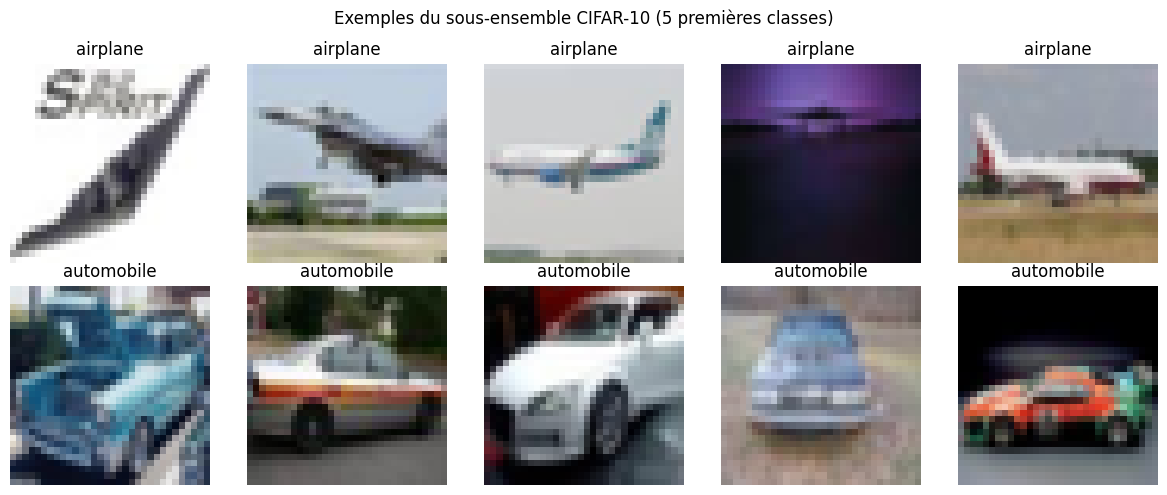

In [3]:
images, labels = C.load_subset()
x_cpu = C.preprocess_images(images, device="cpu")
print("images :", images.shape, images.dtype)
print("tenseur prétraité :", tuple(x_cpu.shape), x_cpu.dtype)
print("distribution :", np.bincount(labels, minlength=len(C.CLASSES)).tolist())
print("classes :", C.CLASSES)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, idx in zip(axes.flat, range(10)):
    ax.imshow(images[idx])
    ax.set_title(C.CLASSES[int(labels[idx])])
    ax.axis("off")
fig.suptitle("Exemples du sous-ensemble CIFAR-10 (5 premières classes)")
plt.tight_layout()
plt.show()

## 2. Modèle commun

In [4]:
model = C.build_model("cpu")
n_params = sum(p.numel() for p in model.parameters())
print(f"ResNet-18 + tête 10 classes : {n_params/1e6:.2f} M paramètres")
print("Couche de classification :", model.fc)
print("Poids de la tête :", C.ARTIFACTS / "classifier_head.npz")

ResNet-18 + tête 10 classes : 11.18 M paramètres
Couche de classification : Linear(in_features=512, out_features=10, bias=True)
Poids de la tête : /workspace/artifacts/classifier_head.npz


## 3. Référence CPU — PyTorch eager

C'est le pipeline « haut niveau → matériel » sans format intermédiaire ni
runtime optimisé : PyTorch exécute directement les opérateurs sur le CPU.

In [5]:
ref_cpu = C.ensure_reference("cpu", x_cpu, labels)
show(ref_cpu)

PyTorch eager (CPU, réf.)  |  device=cpu  |  backend=pytorch-eager


,Métrique,Moyenne,Écart-type,Min,Max
0,Débit (images/s),45.1760,2.6149,42.1624,47.2477
1,Latence (ms/image),22.1964,1.3124,21.1650,23.7178
2,Temps total (s),1.1098,0.0656,1.0583,1.1859
3,Énergie CPU (J),23.6154,0.9753,22.8000,24.7304
4,Énergie CPU/image (J),0.4723,0.0195,0.4560,0.4946
5,Top-1 accuracy,0.9400,0.0000,0.9400,0.9400


Top-1 accuracy = 94.00 %


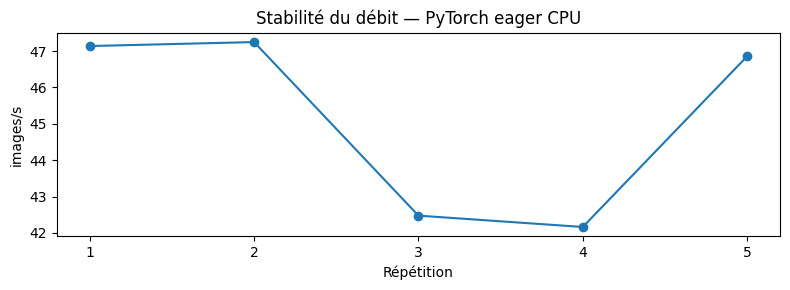

,repetition,throughput_ips,latency_ms_per_image,energy_cpu_j
0,1,47.1389,21.2139,22.8000
1,2,47.2477,21.1650,22.8198
2,3,42.4744,23.5436,24.7304
3,4,42.1624,23.7178,24.6186
4,5,46.8566,21.3417,23.1082


In [6]:
records = pd.DataFrame(ref_cpu["records"])
ax = records.plot(x="repetition", y="throughput_ips", marker="o", legend=False, figsize=(8, 3))
ax.set_xlabel("Répétition")
ax.set_ylabel("images/s")
ax.set_title("Stabilité du débit — PyTorch eager CPU")
ax.set_xticks(records["repetition"])
plt.tight_layout()
plt.show()
records[["repetition", "throughput_ips", "latency_ms_per_image", "energy_cpu_j"]].round(4)

## 4. Référence GPU — PyTorch eager (si GPU disponible)

Sur Colab, sélectionnez un runtime GPU. En local, le conteneur est lancé avec
`--gpus all`.

In [7]:
if torch.cuda.is_available():
    ref_gpu = C.ensure_reference("cuda", x_cpu, labels)
    show(ref_gpu)
else:
    ref_gpu = None
    print("GPU indisponible : la référence GPU ne peut pas être calculée.")

PyTorch eager (GPU, réf.)  |  device=cuda  |  backend=pytorch-eager


,Métrique,Moyenne,Écart-type,Min,Max
0,Débit (images/s),810.7146,3.4286,806.3072,815.7262
1,Latence (ms/image),1.2335,0.0052,1.2259,1.2402
2,Temps total (s),0.0617,0.0003,0.0613,0.0620
3,Énergie CPU (J),0.5642,0.0578,0.4985,0.6077
4,Énergie GPU (J),13.8296,14.8381,0.0000,32.0270
5,Énergie CPU/image (J),0.0113,0.0012,0.0100,0.0122
6,Énergie GPU/image (J),0.4610,0.2205,0.2148,0.6405
7,Mémoire GPU pic (Mo),117.8237,0.0000,117.8237,117.8237
8,Top-1 accuracy,0.9400,0.0000,0.9400,0.9400


Top-1 accuracy = 94.00 %


## 5. Prédictions de la référence CPU

In [8]:
logits = np.load(C.RESULTS / "00_reference_pytorch_cpu_logits.npy")
pred = logits.argmax(axis=1)
df_pred = pd.DataFrame({
    "image": np.arange(len(labels)),
    "vraie classe": [C.CLASSES[int(i)] for i in labels],
    "prédiction": [C.CLASSES[int(i)] for i in pred],
    "correct": pred == labels,
    "confiance": logits.max(axis=1),
})
display(df_pred.head(20).round(3))
print(f"Top-1 sur les 50 images : {C.top1_accuracy(logits, labels) * 100:.2f} %")

,image,vraie classe,prédiction,correct,confiance
0,0,airplane,airplane,True,1.598
1,1,airplane,airplane,True,6.662
2,2,airplane,airplane,True,6.143
3,3,airplane,airplane,True,2.082
4,4,airplane,airplane,True,7.421
5,5,automobile,automobile,True,5.964
6,6,automobile,automobile,True,5.735
7,7,automobile,automobile,True,6.784
8,8,automobile,ship,False,2.854
9,9,automobile,automobile,True,6.413


Top-1 sur les 50 images : 94.00 %


## 6. Comparaison CPU / GPU de la référence

Les deux exécutions utilisent exactement les mêmes poids et les mêmes entrées.
L'écart de débit attendu est important : le GPU est conçu pour les opérations
matricielles massives, tandis que le CPU reste limité par ses cœurs et sa
hiérarchie mémoire.

,id,pipeline,device,backend,throughput_ips,throughput_std,latency_ms,latency_std,accuracy,energy_per_image_j,energy_per_image_std,energy_source
0,00_reference_pytorch_cpu,"PyTorch eager (CPU, réf.)",cpu,pytorch-eager,45.1760,2.6149,22.1964,1.3124,0.94,0.4723,0.0195,cpu_rapl
1,00_reference_pytorch_gpu,"PyTorch eager (GPU, réf.)",cuda,pytorch-eager,810.7146,3.4286,1.2335,0.0052,0.94,0.0701,0.0109,gpu_loop


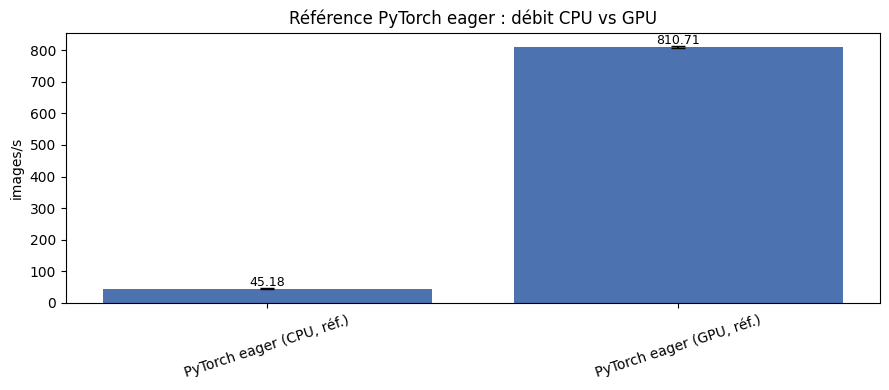

,id,pipeline,device,backend,throughput_ips,throughput_std,latency_ms,latency_std,accuracy,energy_per_image_j,energy_per_image_std,energy_source
0,00_reference_pytorch_cpu,"PyTorch eager (CPU, réf.)",cpu,pytorch-eager,45.175995,2.614870,22.196418,1.312366,0.94,0.472308,0.019506,cpu_rapl
1,00_reference_pytorch_gpu,"PyTorch eager (GPU, réf.)",cuda,pytorch-eager,810.714559,3.428623,1.233497,0.005211,0.94,0.070059,0.010933,gpu_loop


In [9]:
ids = ["00_reference_pytorch_cpu"]
if ref_gpu is not None:
    ids.append("00_reference_pytorch_gpu")
table = pd.DataFrame(C.comparison_rows(ids))
display(table.round(4))
bar_metric(ids, "throughput_ips", "throughput_std", "images/s",
           "Référence PyTorch eager : débit CPU vs GPU")

### Interprétation

La référence mesure le coût des opérateurs PyTorch sans optimisation de
déploiement. Les notebooks suivants vont comparer chaque pipeline optimisé à
cette base. La variabilité (écart-type) est calculée sur les 5 répétitions :
elle permet de distinguer un vrai gain d'un simple bruit de mesure.